In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_classification
import numpy as np
x, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [4]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.8)

In [5]:
reg = LogisticRegression()
reg.fit(xtrain, ytrain)

acc = accuracy_score(ytest, reg.predict(xtest))
print(acc)

1.0


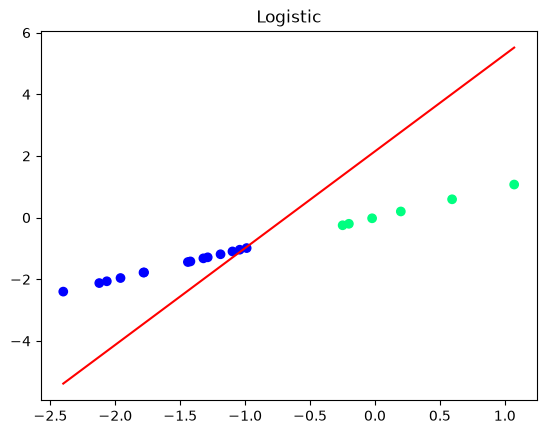

In [6]:
plt.scatter(xtest[:,0],xtest[:,0],c=ytest,cmap='winter')

w1=reg.coef_[0][0]
w2=reg.coef_[0][1]
c=reg.intercept_[0]

x1_range=np.linspace(xtest[:,0].min(),xtest[:,0].max(),100)
x2_range=np.linspace(xtest[:,1].min(),xtest[:,1].max(),100)
y= (w1 * x1_range) + (w2*x2_range) + c
plt.plot(x1_range,y,color='red')
plt.title('Logistic')
plt.show()


In [7]:
print(f" x shape: {x.shape}, y shape: {y.shape}")

 x shape: (100, 2), y shape: (100,)


In [34]:
def loss(x,y) :
    x=np.insert(x,0,1,axis=1)
    w=np.ones(x.shape[1])
    lr=0.01
    for i in range(10000) :
        y_hat=sigmoid(np.dot(x,w))
        w=w+ lr * (np.dot((y-y_hat),x))/x.shape[0]
    return w[0],w[1:]
def sigmoid(z) :
    return 1/(1+(np.exp(-z)))

In [35]:
cp,wp=loss(xtrain,ytrain)

In [36]:
print(cp)
print(wp)

2.7451053355825143
[4.35812173 0.02546251]


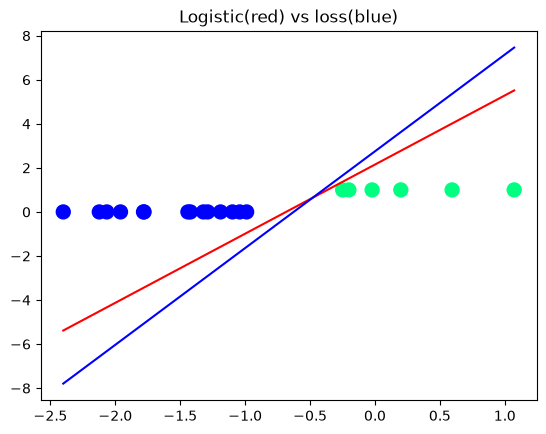

In [37]:
plt.scatter(xtest[:,0],ytest,c=ytest,cmap='winter',s=100)

w1=reg.coef_[0][0]
w2=reg.coef_[0][1]
c1=reg.intercept_[0]

x1_range=np.linspace(xtest[:,0].min(),xtest[:,0].max(),20)
x2_range=np.linspace(xtest[:,1].min(),xtest[:,1].max(),20)
y= (w1 * x1_range) + (w2*x2_range) + c1
y2=(wp[0] * x1_range) + (wp[1] * x2_range) + cp
plt.plot(x1_range,y,color='red')
plt.plot(x1_range,y2,color='blue')
plt.title('Logistic(red) vs loss(blue)')
plt.show()